In [1]:
import torch
from torch import nn
from torchsummary import summary
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torchvision import transforms, models
import kagglehub
import cv2
from glob import glob
import shutil
import matplotlib.pyplot as plt


c:\Users\pomaa\miniconda3\envs\cv2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
tr_directory = './horse-or-human/horse-or-human/train'
test_directory = './horse-or-human/horse-or-human/validation'

## comparing custom neural network to pretrained model

In [4]:
class HorseOrHuman(Dataset):
    def __init__(self, folder):
        horse = glob(folder+'/horses/*.png')
        humans = glob(folder+'/humans/*.png')
        self.inputs = horse[:500] + humans[:500]
        
        from random import shuffle, seed
        shuffle(self.inputs)
        
        seed(10)
        
        self.targets = [fpath.split('/')[-1].startswith('horse') for fpath in self.inputs]
        
    def __len__(self):
        return len(self.inputs)
    
    def __getitem__(self, index):
        image = self.inputs[index]
        target = self.targets[index]
        image = cv2.imread(image)[:,:,::-1]
        image = cv2.resize(image, (224, 224))
        image = torch.tensor(image/255).permute(2, 0, 1).float()
        return image, torch.tensor([target]).float()

In [5]:
def get_data():
    tr_dataset = HorseOrHuman(tr_directory)
    test_dataset = HorseOrHuman(test_directory)
    
    tr_dataloader = DataLoader(tr_dataset, batch_size=32, shuffle=True, drop_last=True)
    test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=True, drop_last=True)
    return tr_dataloader, test_dataloader

tensor([0.])


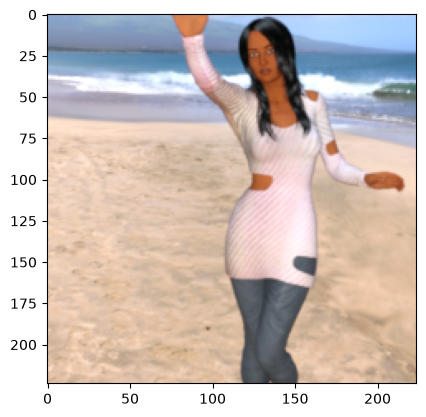

In [6]:
data = HorseOrHuman(tr_directory)
img, label = data[20]
print(label)
plt.imshow(img.permute(1,2,0))

In [7]:
tr_dataloader, test_dataloader = get_data()

### custom CNN model

In [8]:
def conv_layer(ni, no, kernel_size, stride=1):
    return nn.Sequential(
        nn.Conv2d(ni, no, kernel_size, stride),
        nn.ReLU(),
        # nn.BatchNorm2d(no),
        nn.MaxPool2d(2)
    )
    
def get_model():
    model = nn.Sequential(
        conv_layer(3, 64, 3),
        conv_layer(64, 128, 3),
        conv_layer(128, 512, 3),
        conv_layer(512, 512, 3),
        nn.AdaptiveAvgPool2d((1,1)),
        nn.Flatten(),
        nn.Dropout(0.25),
        nn.Linear(512, 1),
        nn.Sigmoid()
    ).to(device)
    loss_fn = nn.BCELoss()
    optimizer = Adam(model.parameters(), lr=0.001)
    return model, loss_fn, optimizer

In [9]:
model, loss, opt = get_model()
summary(model, torch.zeros(1, 3, 224, 224))


Layer (type:depth-idx)                   Output Shape              Param #
├─Sequential: 1-1                        [-1, 64, 111, 111]        --
|    └─Conv2d: 2-1                       [-1, 64, 222, 222]        1,792
|    └─ReLU: 2-2                         [-1, 64, 222, 222]        --
|    └─MaxPool2d: 2-3                    [-1, 64, 111, 111]        --
├─Sequential: 1-2                        [-1, 128, 54, 54]         --
|    └─Conv2d: 2-4                       [-1, 128, 109, 109]       73,856
|    └─ReLU: 2-5                         [-1, 128, 109, 109]       --
|    └─MaxPool2d: 2-6                    [-1, 128, 54, 54]         --
├─Sequential: 1-3                        [-1, 512, 26, 26]         --
|    └─Conv2d: 2-7                       [-1, 512, 52, 52]         590,336
|    └─ReLU: 2-8                         [-1, 512, 52, 52]         --
|    └─MaxPool2d: 2-9                    [-1, 512, 26, 26]         --
├─Sequential: 1-4                        [-1, 512, 12, 12]         --
|  

Layer (type:depth-idx)                   Output Shape              Param #
├─Sequential: 1-1                        [-1, 64, 111, 111]        --
|    └─Conv2d: 2-1                       [-1, 64, 222, 222]        1,792
|    └─ReLU: 2-2                         [-1, 64, 222, 222]        --
|    └─MaxPool2d: 2-3                    [-1, 64, 111, 111]        --
├─Sequential: 1-2                        [-1, 128, 54, 54]         --
|    └─Conv2d: 2-4                       [-1, 128, 109, 109]       73,856
|    └─ReLU: 2-5                         [-1, 128, 109, 109]       --
|    └─MaxPool2d: 2-6                    [-1, 128, 54, 54]         --
├─Sequential: 1-3                        [-1, 512, 26, 26]         --
|    └─Conv2d: 2-7                       [-1, 512, 52, 52]         590,336
|    └─ReLU: 2-8                         [-1, 512, 52, 52]         --
|    └─MaxPool2d: 2-9                    [-1, 512, 26, 26]         --
├─Sequential: 1-4                        [-1, 512, 12, 12]         --
|  

In [10]:
def train_model(model, image, target, loss_fn, optimizer):
    model.train()
    prediction = model(image)
    loss = loss_fn(prediction, target)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    return loss.item()

@torch.no_grad()
def validate_model(model, image, target, loss_fn):
    model.eval()
    prediction = model(image)
    loss = loss_fn(prediction, target)
    return loss.item()

@torch.no_grad()
def accuracy(model, image, target):
    model.eval()
    prediction = model(image)
    is_correct = (prediction > 0.5) == target
    return is_correct.cpu().numpy().tolist()
    

In [11]:
model, loss_fn, optimizer = get_model()

In [12]:
tr_losses, val_losses = [], []
tr_accuracies, val_accuracies = [], []

for epoch in range(10):
    print(epoch+1)
    batch_loss, val_batch_loss = 0, 0
    tr_batch_accuracies, val_epoch_accuracies = [], [] 
    for image, target in tr_dataloader:
        image, target = image.to(device), target.to(device)
        loss = train_model(model, image, target, loss_fn, optimizer)
        batch_loss += loss
    tr_loss = batch_loss/len(tr_dataloader)
    print(f"Epoch {epoch+1}: Train Loss = {tr_loss}")
    tr_losses.append(tr_loss)
    
    for image, target in tr_dataloader:
        image, target = image.to(device), target.to(device)
        is_correct = accuracy(model, image, target)
        tr_batch_accuracies.extend(is_correct)
    epoch_acc = np.mean(tr_batch_accuracies)
    tr_accuracies.append(epoch_acc)
    
    for image, target in test_dataloader:
        image, target = image.to(device), target.to(device)
        loss = validate_model(model, image, target, loss_fn)
        val_batch_loss += loss
        is_correct = accuracy(model, image, target)
        val_epoch_accuracies.extend(is_correct)
    epoch_acc = np.mean(val_epoch_accuracies)
    val_epoch_loss = val_batch_loss/len(test_dataloader)
    print(f"Epoch {epoch+1}: Val Loss = {val_epoch_loss}")
    val_losses.append(val_epoch_loss)
    val_accuracies.append(epoch_acc)
    
    
        
        

1
Epoch 1: Train Loss = 0.6905287734923824
Epoch 1: Val Loss = 0.69834303855896
2
Epoch 2: Train Loss = 0.641759249471849
Epoch 2: Val Loss = 0.7208955734968185
3
Epoch 3: Train Loss = 0.5307073343184686
Epoch 3: Val Loss = 0.7317745313048363
4
Epoch 4: Train Loss = 0.43820288488941805
Epoch 4: Val Loss = 1.412659414112568
5
Epoch 5: Train Loss = 0.331685850697179
Epoch 5: Val Loss = 2.9088366627693176
6
Epoch 6: Train Loss = 0.20947356089468924
Epoch 6: Val Loss = 4.843593120574951
7
Epoch 7: Train Loss = 0.2263052559668018
Epoch 7: Val Loss = 6.057524621486664
8
Epoch 8: Train Loss = 0.14210181635233662
Epoch 8: Val Loss = 3.669293090701103
9
Epoch 9: Train Loss = 0.11729094512279957
Epoch 9: Val Loss = 3.585478663444519
10
Epoch 10: Train Loss = 0.087311489147044
Epoch 10: Val Loss = 6.54834920167923


In [14]:
import matplotlib.ticker as mticker

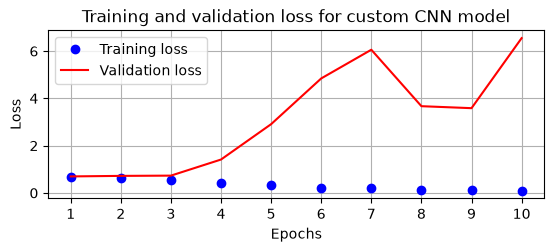

C:\Users\pomaa\AppData\Local\Temp\ipykernel_22424\2072028296.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \


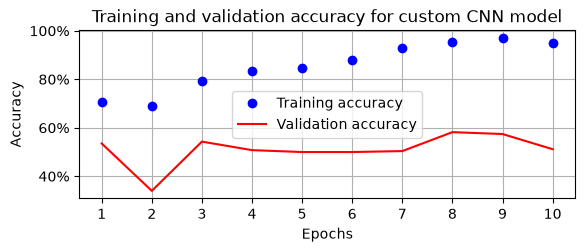

In [15]:
epoch = np.arange(10)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss for custom CNN model')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy for custom CNN model')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \
                           for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()

### Using Pretained model (VGG16)

In [16]:
class HorseOrHuman(Dataset):
    def __init__(self, folder):
        horses = glob(folder+'/horses/*.png')
        humans = glob(folder+'/humans/*.png')
        self.inputs = horses[:500] + humans[:500]
        self.normalize = transforms.Normalize(mean = [0.485,0.456, 0.406], std=[0.229, 0.224, 0.225])
        
        from random import shuffle, seed
        shuffle(self.inputs)
        
        seed(10)
        self.targets =[fpath.split('/')[-1].startswith('horse') for fpath in self.inputs]
        
    def __len__(self):
        return len(self.inputs)
    
    def __getitem__(self, index):
        input = self.inputs[index]
        target = self.targets[index]
        img = cv2.imread(input)[:,:,::-1]
        img = cv2.resize(img, (224, 224))
        img = torch.tensor(img/255).permute(2, 1, 0)
        img = self.normalize(img)
        return img.float(), torch.tensor([target]).float()
    

In [17]:
def get_data():
    tr_dataset = HorseOrHuman(tr_directory)
    test_dataset = HorseOrHuman(test_directory)
    
    tr_dataloader = DataLoader(tr_dataset, batch_size=32, shuffle=True, drop_last=True)
    test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=True, drop_last=True)
    return tr_dataloader, test_dataloader

In [18]:
tr_dataloader, test_dataloader = get_data()

In [19]:
def vgg16():
    model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    
    for params in model.parameters():
        params.requires_grad = False
        
    model.avgpool = nn.AdaptiveAvgPool2d(output_size=(1,1))
    
    model.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(512, 128),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(128, 1),
        nn.Sigmoid()
    )
    loss_fn = nn.BCELoss()
    optimizer = Adam(model.parameters(), lr=0.001)
    return model.to(device), loss_fn, optimizer

In [20]:
def train_model(model, image, target, loss_fn, optimizer):
    model.train()
    prediction = model(image)
    loss = loss_fn(prediction, target)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    return loss.item()

@torch.no_grad()
def validate_model(model, image, target, loss_fn):
    model.eval()
    prediction = model(image)
    loss = loss_fn(prediction, target)
    return loss.item()

@torch.no_grad()
def accuracy(model, image, target):
    model.eval()
    prediction = model(image)
    is_correct = (prediction > 0.5) == target
    return is_correct.cpu().numpy().tolist()
    

In [21]:
model, loss_fn, optimizer = vgg16()

In [22]:
summary(model, torch.zeros(1, 3, 224,224))

Layer (type:depth-idx)                   Output Shape              Param #
├─Sequential: 1-1                        [-1, 512, 7, 7]           --
|    └─Conv2d: 2-1                       [-1, 64, 224, 224]        (1,792)
|    └─ReLU: 2-2                         [-1, 64, 224, 224]        --
|    └─Conv2d: 2-3                       [-1, 64, 224, 224]        (36,928)
|    └─ReLU: 2-4                         [-1, 64, 224, 224]        --
|    └─MaxPool2d: 2-5                    [-1, 64, 112, 112]        --
|    └─Conv2d: 2-6                       [-1, 128, 112, 112]       (73,856)
|    └─ReLU: 2-7                         [-1, 128, 112, 112]       --
|    └─Conv2d: 2-8                       [-1, 128, 112, 112]       (147,584)
|    └─ReLU: 2-9                         [-1, 128, 112, 112]       --
|    └─MaxPool2d: 2-10                   [-1, 128, 56, 56]         --
|    └─Conv2d: 2-11                      [-1, 256, 56, 56]         (295,168)
|    └─ReLU: 2-12                        [-1, 256, 56,

Layer (type:depth-idx)                   Output Shape              Param #
├─Sequential: 1-1                        [-1, 512, 7, 7]           --
|    └─Conv2d: 2-1                       [-1, 64, 224, 224]        (1,792)
|    └─ReLU: 2-2                         [-1, 64, 224, 224]        --
|    └─Conv2d: 2-3                       [-1, 64, 224, 224]        (36,928)
|    └─ReLU: 2-4                         [-1, 64, 224, 224]        --
|    └─MaxPool2d: 2-5                    [-1, 64, 112, 112]        --
|    └─Conv2d: 2-6                       [-1, 128, 112, 112]       (73,856)
|    └─ReLU: 2-7                         [-1, 128, 112, 112]       --
|    └─Conv2d: 2-8                       [-1, 128, 112, 112]       (147,584)
|    └─ReLU: 2-9                         [-1, 128, 112, 112]       --
|    └─MaxPool2d: 2-10                   [-1, 128, 56, 56]         --
|    └─Conv2d: 2-11                      [-1, 256, 56, 56]         (295,168)
|    └─ReLU: 2-12                        [-1, 256, 56,

In [23]:
tr_losses, val_losses = [], []
tr_accuracies, val_accuracies = [], []

for epoch in range(10):
    print(epoch+1)
    batch_loss, val_batch_loss = [], []
    tr_batch_accuracies, val_epoch_accuracies = [], [] 
    for image, target in tr_dataloader:
        image, target = image.to(device), target.to(device)
        loss = train_model(model, image, target, loss_fn, optimizer)
        batch_loss.append(loss)
    tr_loss = np.array(batch_loss).mean()
    print(f"Epoch {epoch+1}: Train Loss = {tr_loss}")
    tr_losses.append(tr_loss)
    
    for image, target in tr_dataloader:
        image, target = image.to(device), target.to(device)
        is_correct = accuracy(model, image, target)
        tr_batch_accuracies.extend(is_correct)
    epoch_acc = np.mean(tr_batch_accuracies)
    tr_accuracies.append(epoch_acc)
    
    for image, target in test_dataloader:
        image, target = image.to(device), target.to(device)
        loss = validate_model(model, image, target, loss_fn)
        val_batch_loss.append(loss)
        is_correct = accuracy(model, image, target)
        val_epoch_accuracies.extend(is_correct)
    epoch_acc = np.mean(val_epoch_accuracies)
    val_epoch_loss = np.array(val_batch_loss).mean()
    print(f"Epoch {epoch+1}: Val Loss = {val_epoch_loss}")
    val_losses.append(val_epoch_loss)
    val_accuracies.append(epoch_acc)
    
    
        
        

1
Epoch 1: Train Loss = 0.281043621080537
Epoch 1: Val Loss = 0.22755509242415428
2
Epoch 2: Train Loss = 0.04098422059248532
Epoch 2: Val Loss = 0.2366360668092966
3
Epoch 3: Train Loss = 0.016782111923901305
Epoch 3: Val Loss = 0.19107467494904995
4
Epoch 4: Train Loss = 0.010713015960889959
Epoch 4: Val Loss = 0.22051382204517722
5
Epoch 5: Train Loss = 0.0071859048574321694
Epoch 5: Val Loss = 0.2281261933967471
6
Epoch 6: Train Loss = 0.0045332316752342925
Epoch 6: Val Loss = 0.20662390813231468
7
Epoch 7: Train Loss = 0.0036114224443031897
Epoch 7: Val Loss = 0.2308882437646389
8
Epoch 8: Train Loss = 0.002918843666256796
Epoch 8: Val Loss = 0.22716043051332235
9
Epoch 9: Train Loss = 0.002114834857263392
Epoch 9: Val Loss = 0.2270147716626525
10
Epoch 10: Train Loss = 0.0017155958527338602
Epoch 10: Val Loss = 0.24148464621976018


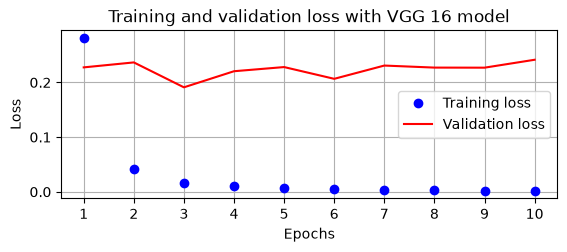

C:\Users\pomaa\AppData\Local\Temp\ipykernel_22424\3292333596.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \


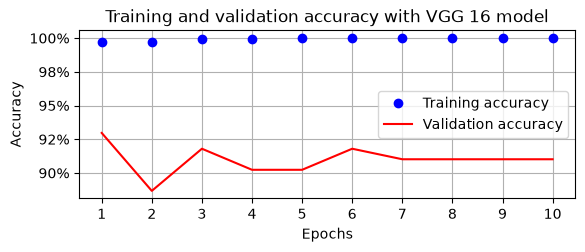

In [24]:
epoch = np.arange(10)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss with VGG 16 model')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy with VGG 16 model')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \
                           for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()